In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
netflix_data = pd.read_csv("netflix_content.csv")
netflix_data.head()

,Title,Available Globally?,Release Date,Hours Viewed,Language Indicator,Content Type
0,The Night Agent: Season 1,Yes,2023-03-23,"81,21,00,000",English,Show
1,Ginny & Georgia: Season 2,Yes,2023-01-05,"66,51,00,000",English,Show
2,The Glory: Season 1 // 더 글로리: 시즌 1,Yes,2022-12-30,"62,28,00,000",Korean,Show
3,Wednesday: Season 1,Yes,2022-11-23,"50,77,00,000",English,Show
4,Queen Charlotte: A Bridgerton Story,Yes,2023-05-04,"50,30,00,000",English,Movie


In [3]:
netflix_data.isnull().sum()

Title                      0
Available Globally?        0
Release Date           16646
Hours Viewed               0
Language Indicator         0
Content Type               0
dtype: int64

In [4]:
netflix_data["Release Date"] = pd.to_datetime(netflix_data["Release Date"], errors='coerce')

In [5]:
netflix_data.head()

,Title,Available Globally?,Release Date,Hours Viewed,Language Indicator,Content Type
0,The Night Agent: Season 1,Yes,2023-03-23,"81,21,00,000",English,Show
1,Ginny & Georgia: Season 2,Yes,2023-01-05,"66,51,00,000",English,Show
2,The Glory: Season 1 // 더 글로리: 시즌 1,Yes,2022-12-30,"62,28,00,000",Korean,Show
3,Wednesday: Season 1,Yes,2022-11-23,"50,77,00,000",English,Show
4,Queen Charlotte: A Bridgerton Story,Yes,2023-05-04,"50,30,00,000",English,Movie


In [6]:
# Pehle commas hata kar numeric (int) mein convert karein
netflix_data["Hours Viewed"] = netflix_data["Hours Viewed"].astype(str).str.replace(",", "").astype(int)

In [7]:
netflix_data.dtypes

Title                             str
Available Globally?               str
Release Date           datetime64[us]
Hours Viewed                    int64
Language Indicator                str
Content Type                      str
dtype: object

# Top 10 titles have the highest viewing hours

In [8]:
top_10_title = netflix_data.groupby("Title")["Hours Viewed"].sum().sort_values(ascending=False).head(10)
top_10_title

Title
The Night Agent: Season 1                          967600000
Ginny & Georgia: Season 2                          731300000
The Glory: Season 1 // 더 글로리: 시즌 1                 689700000
Wednesday: Season 1                                670400000
King the Land: Limited Series // 킹더랜드: 리미티드 시리즈    665400000
Queen Charlotte: A Bridgerton Story                580600000
ONE PIECE: Season 1                                541900000
La Reina del Sur: Season 3                         498900000
You: Season 4                                      471400000
Outer Banks: Season 3                              445300000
Name: Hours Viewed, dtype: int64

<Axes: ylabel='Title'>

C:\Users\Acer\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 45908 (\N{HANGUL SYLLABLE DEO}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\Users\Acer\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 44544 (\N{HANGUL SYLLABLE GEUL}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\Users\Acer\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 47196 (\N{HANGUL SYLLABLE RO}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\Users\Acer\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\Users\Acer\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from fo

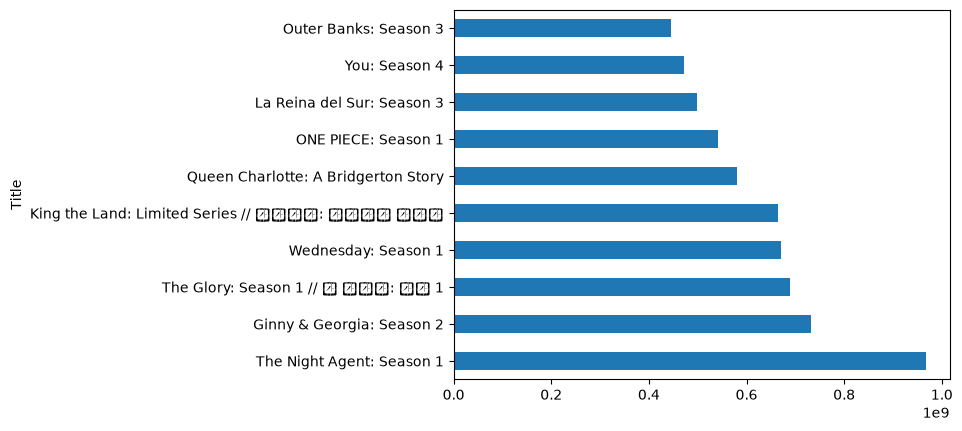

In [16]:
top_10_title.plot(kind="barh")

# Movies or Shows generate more total viewing hours

In [12]:
movies_or_show = netflix_data.groupby("Content Type")["Hours Viewed"].sum().sort_values(ascending=False)
movies_or_show

Content Type
Show     107764100000
Movie     50637800000
Name: Hours Viewed, dtype: int64

Text(0.5, 1.0, 'Movies Vs Show')

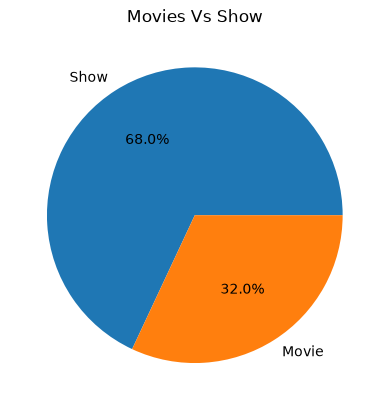

In [18]:
plt.pie(movies_or_show.values,labels=movies_or_show.index,autopct="%1.1f%%")
plt.title("Movies Vs Show")

# content type has the higher average viewing hours per title

In [19]:
avg_viewing_hours = netflix_data.groupby("Content Type")["Hours Viewed"].mean().sort_values(ascending=False)
avg_viewing_hours

Content Type
Show     1.006389e+07
Movie    3.590315e+06
Name: Hours Viewed, dtype: float64

Text(0.5, 1.0, 'Avg Viewing Hours')

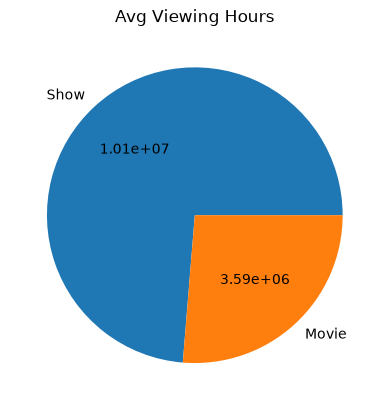

In [27]:
plt.pie(avg_viewing_hours.values,labels=avg_viewing_hours.index,autopct=lambda p: f'{p * sum(avg_viewing_hours.values) / 100:.2e}',)
plt.title("Avg Viewing Hours")

# Percentage of total viewing hours comes from the top 10 titles

In [28]:
top_10_hours = top_10_title.sum()
total_hours = netflix_data["Hours Viewed"].sum()
top_10_percentage = round((top_10_hours/total_hours)*100,2)
print(top_10_percentage,"%")

3.95 %


# Globally available titles receive more viewing hours than other titles

In [29]:
globle_impact = netflix_data.groupby("Available Globally?")["Hours Viewed"].mean().sort_values(ascending=False)
globle_impact

Available Globally?
Yes    1.114549e+07
No     4.261677e+06
Name: Hours Viewed, dtype: float64

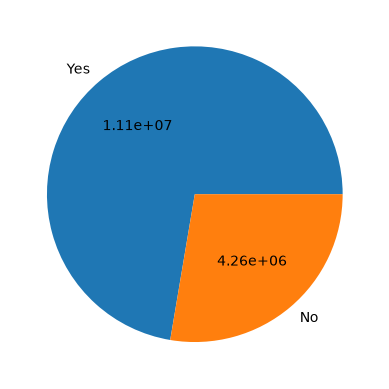

In [30]:
plt.pie(globle_impact.values,labels=globle_impact.index,autopct=lambda p: f'{p * sum(globle_impact.values) / 100:.2e}',)

# Languages generate the highest viewing hours

In [31]:
top_language = netflix_data.groupby("Language Indicator")["Hours Viewed"].sum().sort_values(ascending=False)
top_language

Language Indicator
English        124441700000
Korean          15378400000
Non-English     10439100000
Japanese         7102000000
Hindi             926100000
Russian           114600000
Name: Hours Viewed, dtype: int64

<Axes: xlabel='Language Indicator', ylabel='Hours Viewed'>

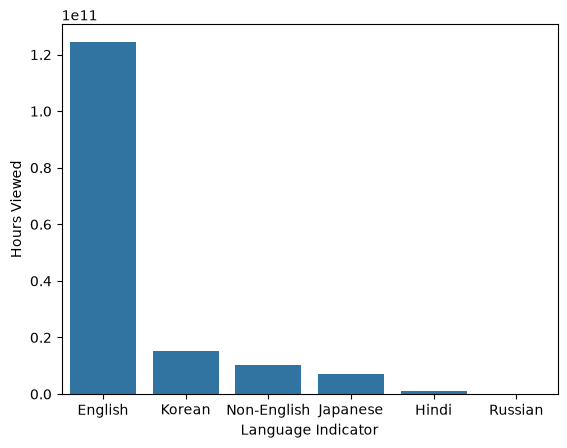

In [32]:
sns.barplot(top_language)

# Viewing performance differ between English and non-English content

In [33]:
english_vs_non_english = netflix_data.groupby("Language Indicator")["Hours Viewed"].agg(["sum","mean","count"])
english_vs_non_english

,sum,mean,count
Language Indicator,,,
English,124441700000,7.206492e+06,17268
Hindi,926100000,2.476203e+06,374
Japanese,7102000000,3.091859e+06,2297
Korean,15378400000,9.720860e+06,1582
Non-English,10439100000,3.210055e+06,3252
Russian,114600000,2.938462e+06,39


 # Relationship between release date and viewing hours

In [34]:
netflix_data["Release Year"] = netflix_data["Release Date"].dt.year

In [35]:
yearly_trend = netflix_data.groupby("Release Year")["Hours Viewed"].agg(["sum","mean","count"])
yearly_trend

,sum,mean,count
Release Year,,,
2010.0,125500000,7.843750e+06,16
2011.0,155500000,2.591667e+07,6
2012.0,6300000,3.150000e+06,2
2013.0,260600000,1.240952e+07,21
2014.0,507900000,1.036531e+07,49
2015.0,1082200000,7.361905e+06,147
2016.0,2206800000,6.567857e+06,336
2017.0,3998600000,6.709060e+06,596
2018.0,4621800000,4.745175e+06,974


<Axes: xlabel='Release Year'>

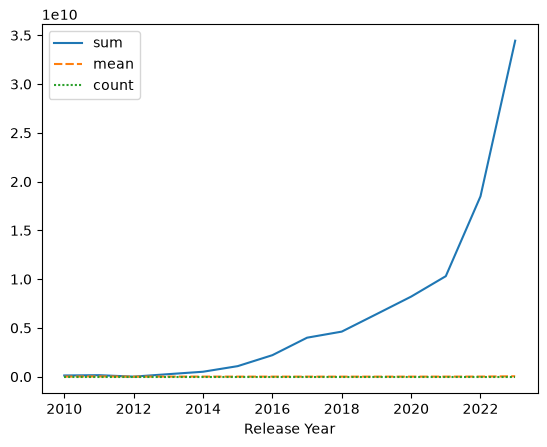

In [36]:
sns.lineplot(yearly_trend)

# Titles have missing release dates

In [37]:
missing_date = netflix_data["Release Date"].isnull().sum()
print("Missing Release Dates:", missing_date)

Missing Release Dates: 16646


# Final Recommendation

### TV Shows vs Movies: Kyunki Shows ke total viewing hours aur average viewing hours Movies se kaafi zyada hain, isliye Netflix ko future content acquisition mein TV Shows par zyada budget allocate karna chahiye

### Language Expansion: Total viewing hours mein English sabse aage hai, uske baad Korean aur Non-English content aata hai. Per-title average mein Korean sabse upar hai (9.7M hours). Isliye Netflix ko English ke saath-saath Korean aur Non-English content banane par bhi dhyaan dena chahiye, kyunki ye faydemand hoga.

### Global Availability: Globally available titles ko prioritize karna chahiye kyunki yeh wider audience tak pahunch kar zyada total viewing hours generate karte hain.

### Recent Releases: Jaise trend table mein dikh raha hai, recent years (2022-2023) mein viewing hours ka volume bahut high hai, isliye fresh original content pipeline ko strong rakhna zaroori hai

In [73]:
netflix_data.to_csv("netflix_cleaned.csv", index=False)